In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
Пусть Xi ∼ N (0, 1).
1) Построить эмпирическую функцию распределения (ЭФР) на одном графике с теоретической
функцией распределения при разных n (проиллюстрировать сходимость ЭФР к ф.р.). То же для
Xi ∼ R[0, 1], Xi ∼ Bin(m, p), где m = 3, m = 10.

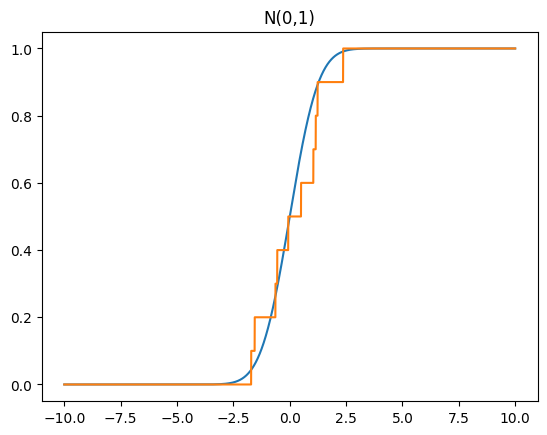

In [11]:
n=10
x=np.random.normal(0,1,size=n)
l=np.linspace(-10,10,10000)
plt.plot(l, sc.stats.norm.cdf(l,0,1))
plt.plot(l, sc.stats.ecdf(x).cdf.evaluate(l))
plt.title("N(0,1)")
plt.show()

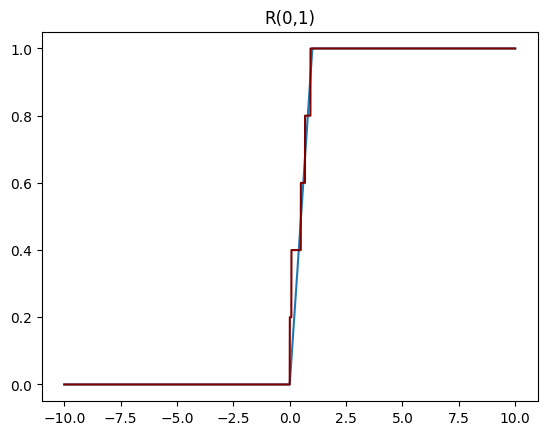

In [16]:
n=5
x=np.random.uniform(0,1,size=n)
l=np.linspace(-10,10,10000)
plt.plot(l, sc.stats.uniform.cdf(l,0,1))
plt.plot(l, sc.stats.ecdf(x).cdf.evaluate(l), color = "#800000")
plt.title("R(0,1)")
plt.show()

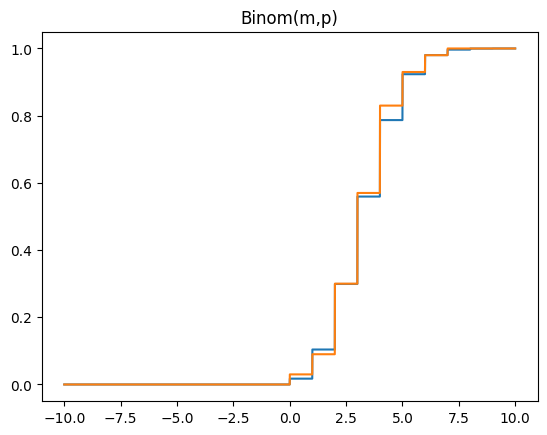

In [22]:
n=100
m=3
p=1/3
x=np.random.binomial(m, p, size=n)
l=np.linspace(-10,10,10000)
plt.plot(l, sc.stats.binom.cdf(l,m,p))
plt.plot(l, sc.stats.ecdf(x).cdf.evaluate(l))
plt.title("Binom(m,p)")
plt.show()

In [ ]:
2) Построить 95% доверительную полосу для ф.р., используя а) критерий Колмогорова. б) нера-
венство Дворецкого-Кифера-Вольфовица.

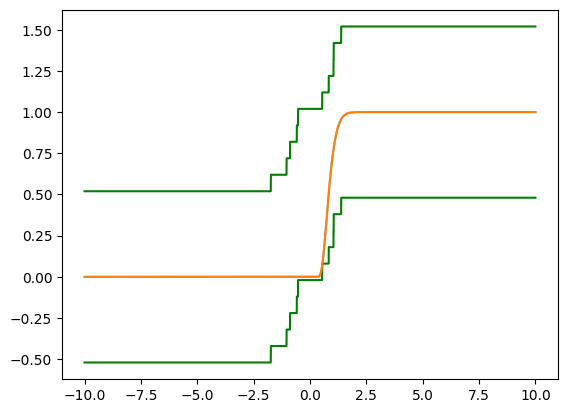

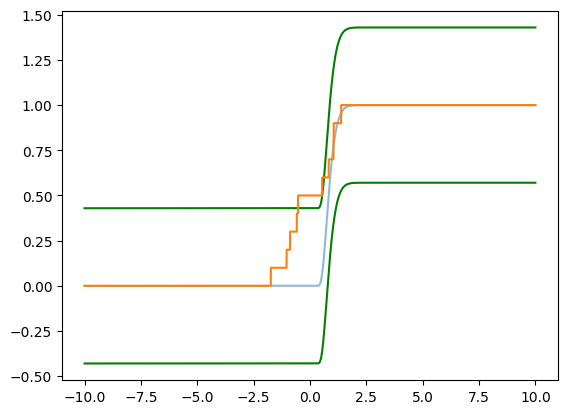

In [2]:
n=10
x=np.random.normal(0,1,size=n)
l=np.linspace(-10,10,10000)
plt.plot(l, sc.stats.kstwobign.cdf(l), alpha=0.5)
eps=sc.stats.kstwobign.ppf(0.05)
plt.plot(l,sc.stats.ecdf(x).cdf.evaluate(l)+eps, color="green")
plt.plot(l, sc.stats.ecdf(x).cdf.evaluate(l)-eps, color="green")
plt.plot(l, sc.stats.kstwobign.cdf(l))
plt.show()

eps = np.sqrt(np.log(0.05/2) / (-2*n))
plt.plot(l, sc.stats.kstwobign.cdf(l), alpha=0.5)
plt.plot(l, sc.stats.kstwobign.cdf(l)+eps, color="green")
plt.plot(l, sc.stats.kstwobign.cdf(l)-eps, color="green")
plt.plot(l, sc.stats.ecdf(x).cdf.evaluate(l))
plt.show()

In [ ]:
2. С помощью критерия Колмогорова проверить гипотезу H0 : Xi ∼ N (0, 1), если
Xi = (Yi − EYi)/√DYi
, где
(a) Yi ∼ N (−3, 8),
(b) Yi ∼ Bin(m, 1/2),
(c) Yi имеют распределение Ирвина–Холла (сумма m независимых равномерных с.в.).

50 0.04


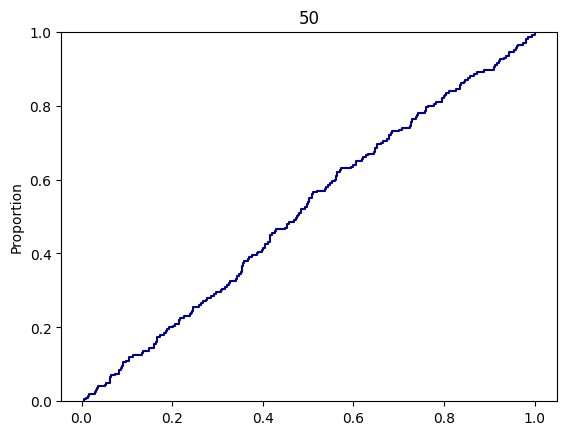

100 0.045


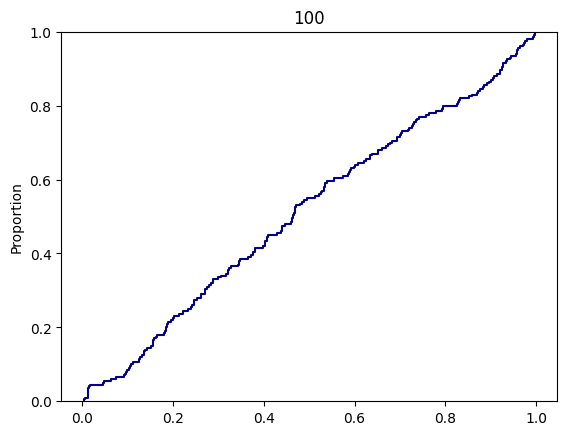

500 0.049999999999999996


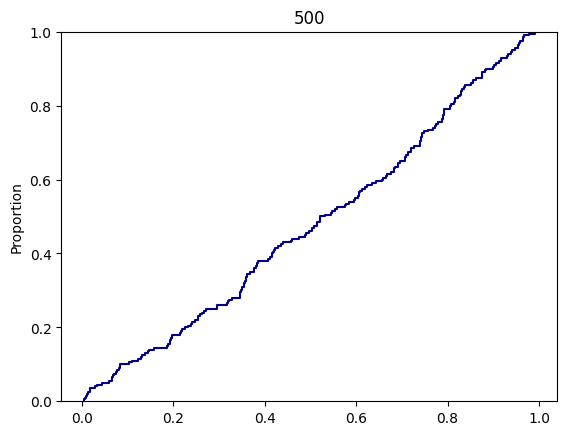

In [33]:
numbers = [50,100,500]
k = 200
eps=sc.stats.kstwobign.ppf(0.95)
for n in numbers:
    count = 0
    pval = [0]*k
    for j in range(k):
        y = np.random.normal(-3,np.sqrt(8),size=n)
        x = [(a+3)/np.sqrt(8) for a in y]
        x = np.sort(x)
        stat, pval[j] = sc.stats.kstest(x, 'norm', args=(0, 1))
        if np.sqrt(n)*stat >eps:
            count+=1/k
    print(n, count)
    sb.ecdfplot(pval, color = "#00008B")
    plt.title(n)
    plt.show()

50 0.29500000000000015


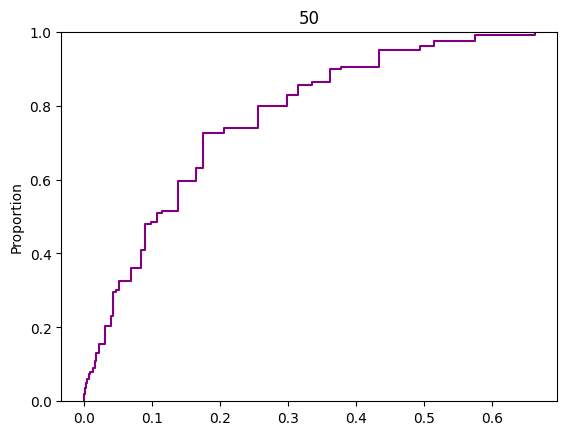

100 0.5000000000000003


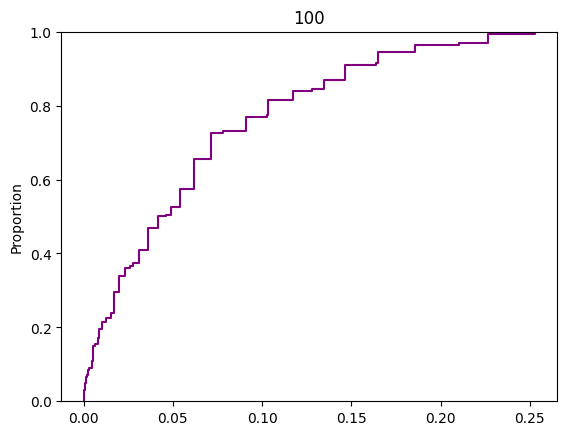

500 1.0000000000000007


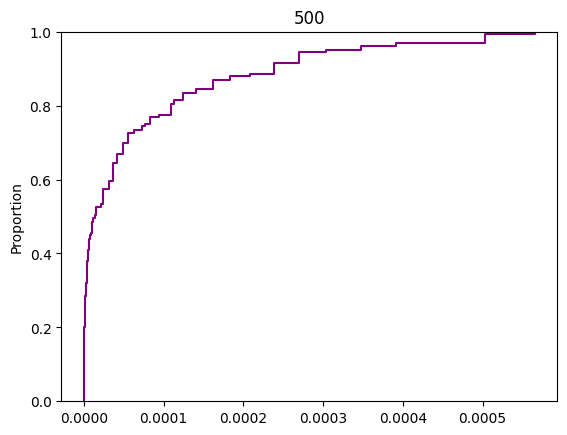

In [3]:
numbers = [50,100,500]
k = 200
m = 20
eps=sc.stats.kstwobign.ppf(0.95)
for n in numbers:
    count = 0
    pval = [0]*k
    for j in range(k):
        y = np.random.binomial(m,1/2,size=n)
        x = [(a-m/2)/np.sqrt(m*0.25) for a in y]
        x = np.sort(x)
        stat, pval[j] = sc.stats.kstest(x, 'norm', args=(0, 1))
        if np.sqrt(n)*stat > eps:
            count+=1/k
    print(n, count)
    sb.ecdfplot(pval, color = "purple")
    plt.title(n)
    plt.show()

50 0.035


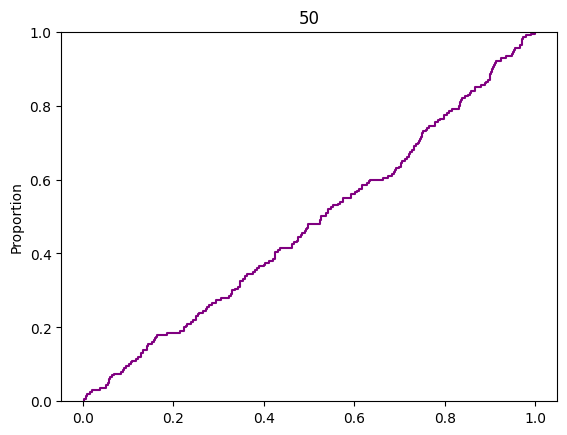

100 0.04


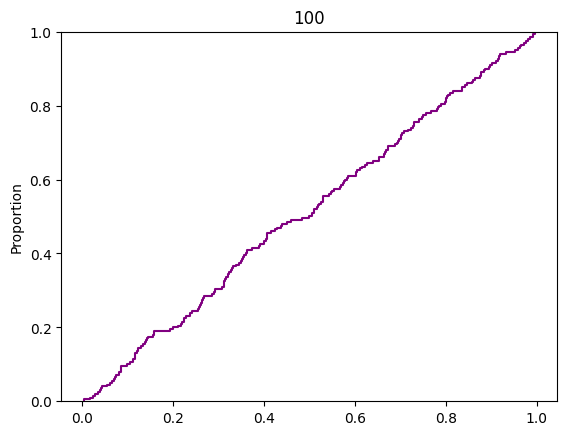

500 0.045


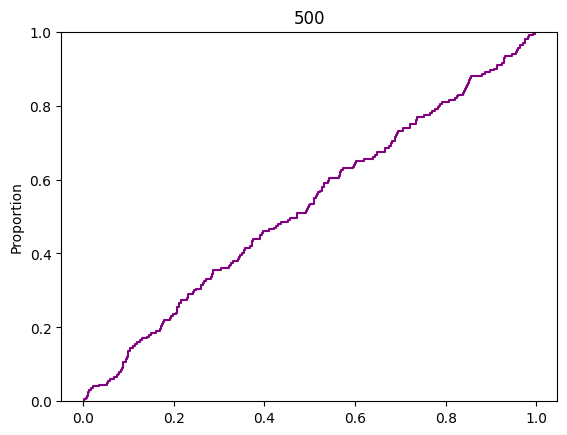

In [32]:
numbers = [50,100,500]
k = 200
m = 10
eps=sc.stats.kstwobign.ppf(0.95)
for n in numbers:
    count = 0
    pval = [0]*k
    for j in range(k):
        y = sc.stats.irwinhall.rvs(m,size = n)
        x = [(a-m/2)/np.sqrt(m/12) for a in y]
        x = np.sort(x)
        stat, pval[j] = sc.stats.kstest(x, 'norm', args=(0, 1))
        if np.sqrt(n)*stat > eps:
            count+=1/k
    print(n, count)
    sb.ecdfplot(pval, color = "purple")
    plt.title(n)
    plt.show()

In [ ]:
3. Если выборка имеет нормальное распределение с неизвестными параметрами, то можно попробо-
вать перейти от выборки Xi к (Xi−X)/S и применить к ним критерий Колмогорова нормальности

N (0, 1). Построить график p-value при верной гипотезе и посмотреть корректно ли работает ”мо-
дифицированный” критерий.

50 0


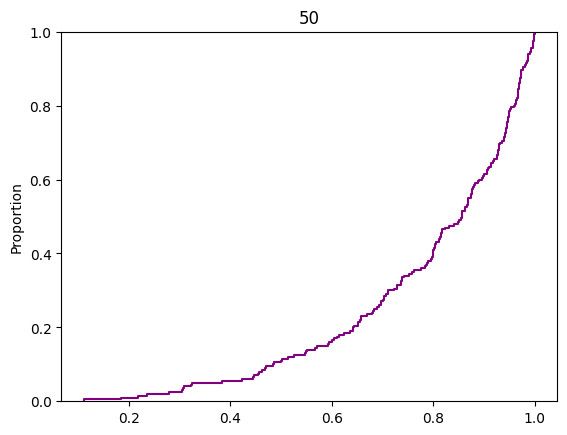

100 0


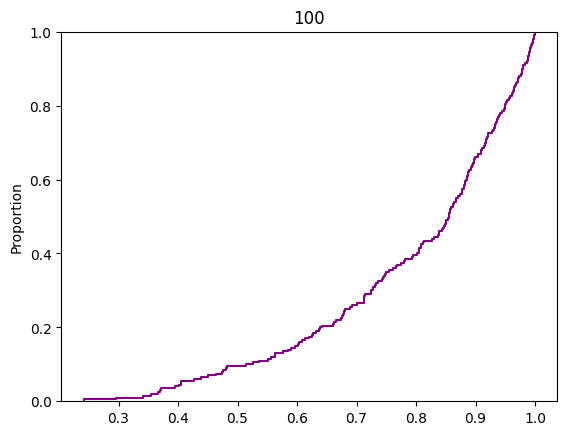

500 0


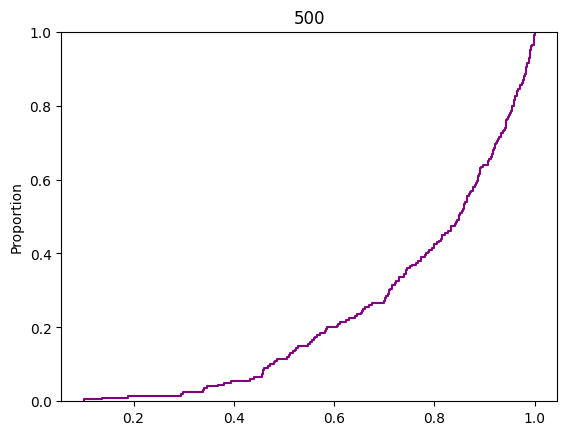

In [50]:
numbers = [50,100,500]
k = 200
mu = 3
sigma = 8
eps=sc.stats.kstwobign.ppf(0.95)
for n in numbers:
    count = 0
    pval = [0]*k
    for j in range(k):
        y = np.random.normal(mu,sigma,size=n)
        x = [(a-np.mean(y))/np.std(y) for a in y]
        #x = [(a-mu)/sigma for a in y]
        x = np.sort(x)
        stat, pval[j] = sc.stats.kstest(x, 'norm', args=(0, 1))
        if np.sqrt(n)*stat > eps:
            count+=1/k
    print(n, count)
    sb.ecdfplot(pval, color = "purple")
    plt.title(n)
    plt.show()